In [1]:
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
plt.rc('figure', autolayout=True)
plt.rc('axes', labelweight='bold', labelsize='large',
       titleweight='bold', titlesize=18, titlepad=10)
plt.rc('animation', html='html5')

In [2]:
import pandas as pd

from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

hotel = pd.read_csv('../datasets/dl-course-data/hotel.csv')

X = hotel.copy()
y = X.pop('is_canceled')

CLASSES = {
    'January': 1, 'February': 2, 'March': 3,
    'April': 4, 'May': 5, 'June': 6,
    'July': 7, 'August': 8, 'September': 9,
    'October': 10, 'November': 11, 'December': 12
}

X['arrival_date_month'] = X['arrival_date_month'].map(CLASSES)
features_num = [
    "lead_time", "arrival_date_week_number",
    "arrival_date_day_of_month", "stays_in_weekend_nights",
    "stays_in_week_nights", "adults", "children", "babies",
    "is_repeated_guest", "previous_cancellations",
    "previous_bookings_not_canceled", "required_car_parking_spaces",
    "total_of_special_requests", "adr",
]
features_cat = [
    "hotel", "arrival_date_month", "meal",
    "market_segment", "distribution_channel",
    "reserved_room_type", "deposit_type", "customer_type",
]

transformer_num = make_pipeline(
    SimpleImputer(strategy="constant"), # there are a few missing values
    StandardScaler(),
)

transformer_cat = make_pipeline(
    SimpleImputer(strategy="constant", fill_value="NA"),
    OneHotEncoder(handle_unknown='ignore'),
)

preprocessor = make_column_transformer(
    (transformer_num, features_num),
    (transformer_cat, features_cat),
)

# stratify - make sure classes are evenlly represented across splits
X_train, X_valid, y_train, y_valid = train_test_split(X, y, stratify=y, train_size=0.75)

X_train = preprocessor.fit_transform(X_train)
X_valid = preprocessor.transform(X_valid)

INPUT_SHAPE = [X_train.shape[1]]

In [5]:
from tensorflow.keras import Sequential, callbacks, layers

HIDDEN_SHAPE, OUTPUT_SHAPE = 256, 1
ReLU, SIGMOID = 'relu', 'sigmoid'
DROPOUT_RATE = 0.3

# Define the model
model = Sequential([
    layers.Input(shape=INPUT_SHAPE),
    layers.BatchNormalization(),
    
    layers.Dense(HIDDEN_SHAPE, activation=ReLU),
    layers.BatchNormalization(),
    layers.Dropout(DROPOUT_RATE),

    layers.Dense(HIDDEN_SHAPE, activation=ReLU),
    layers.BatchNormalization(),
    layers.Dropout(DROPOUT_RATE),

    layers.Dense(OUTPUT_SHAPE, activation=SIGMOID),
])

In [6]:
# Compile the model with the Adam optimizer and binary versions of the cross-entropy loss and accuracy metric.
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['binary_accuracy'],
)

Epoch 1/200


2025-01-23 12:06:39.718491: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 22564584 exceeds 10% of free system memory.


175/175 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - binary_accuracy: 0.7410 - loss: 0.5385 - val_binary_accuracy: 0.7966 - val_loss: 0.4334
Epoch 2/200
175/175 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - binary_accuracy: 0.8008 - loss: 0.4266 - val_binary_accuracy: 0.8131 - val_loss: 0.4046
Epoch 3/200
175/175 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - binary_accuracy: 0.8087 - loss: 0.4097 - val_binary_accuracy: 0.8161 - val_loss: 0.3964
Epoch 4/200
175/175 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - binary_accuracy: 0.8130 - loss: 0.4031 - val_binary_accuracy: 0.8176 - val_loss: 0.3927
Epoch 5/200
175/175 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - binary_accuracy: 0.8136 - loss: 0.4003 - val_binary_accuracy: 0.8214 - val_loss: 0.3893
Epoch 6/200
175/175 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - binary_accuracy: 0.8184 - loss: 0.3900 - val_binary_accuracy: 0.8221 - val_loss: 0.3857
Epoch 7/200
175/175 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - binary_accuracy: 0.8188 - loss: 0.3880 - val_binary_accuracy: 0.8232 - val_loss: 0.3832
Epoc

<Axes: title={'center': 'Accuracy'}>

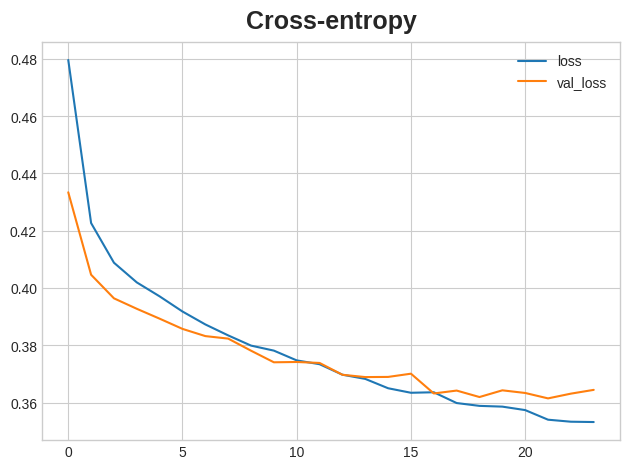

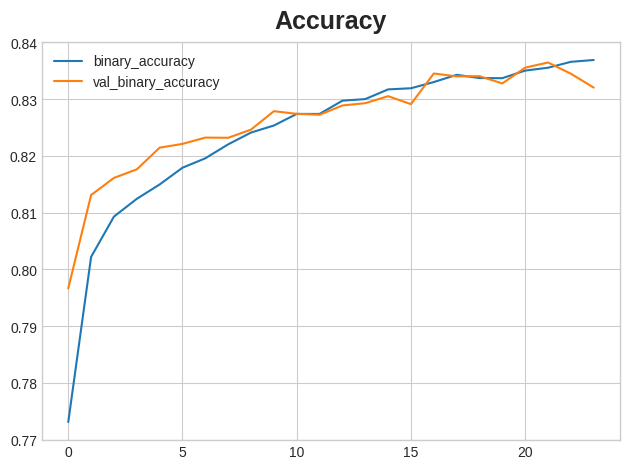

In [7]:
EPOCHS = 200

early_stopping = callbacks.EarlyStopping(
    patience=5,
    min_delta=0.001,
    restore_best_weights=True,
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=512,
    epochs=EPOCHS,
    callbacks=[early_stopping],
    verbose=0,
)

history_df = pd.DataFrame(history.history)
history_df.loc[:, ['loss', 'val_loss']].plot(title="Cross-entropy")
history_df.loc[:, ['binary_accuracy', 'val_binary_accuracy']].plot(title="Accuracy")

In [8]:
from IPython.display import display, Markdown

content = f"""
**Q**: **What do you think about the learning curves? 
Does it look like the model underfit or overfit? 
Was the cross-entropy loss a good stand-in for accuracy?**<br>
**A**: Though we can see the training loss continuing to fall, the early stopping callback prevented 
any overfitting. Moreover, the accuracy rose at the same rate as the cross-entropy fell, so it appears 
that minimizing cross-entropy was a good stand-in. All in all, it looks like this training was a success!
"""

display(Markdown(content))


**Q**: **What do you think about the learning curves? 
Does it look like the model underfit or overfit? 
Was the cross-entropy loss a good stand-in for accuracy?**<br>
**A**: Though we can see the training loss continuing to fall, the early stopping callback prevented 
any overfitting. Moreover, the accuracy rose at the same rate as the cross-entropy fell, so it appears 
that minimizing cross-entropy was a good stand-in. All in all, it looks like this training was a success!
